In [1]:
import torch

In [2]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
device

device(type='cpu')

In [11]:
x=torch.linspace(-2,2,50).unsqueeze(1)

In [12]:
x

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [16]:
noise=0.6 * torch.randn_like(x)
y=3*x+2 + noise

In [9]:
import matplotlib.pyplot as plt

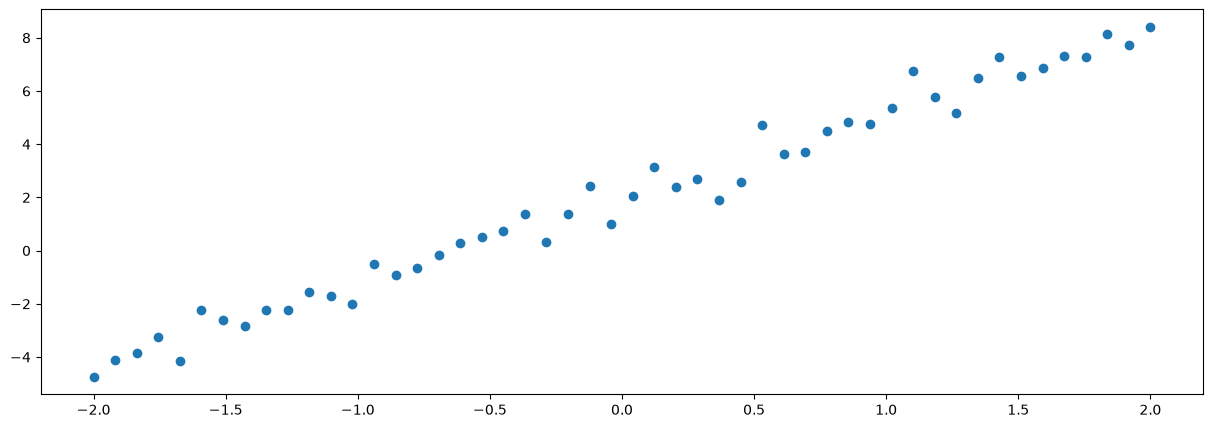

In [17]:
plt.figure(figsize=(15,5))
plt.scatter(x,y)

In [18]:
import torch.nn as nn

In [19]:
model = nn.Linear(1,1)

In [43]:
loss_func=nn.MSELoss()
optimizer=torch.optim.Adam(model.parameters(),lr=0.1)
epochs=100
losses=[]
for epoch in range(epochs):
    y_pred=model(x)
    loss=loss_func(y_pred,y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch%100==0:
        print(f"Epoch {epoch}/{epochs}, Loss: {loss.item()}")

Epoch 0/100, Loss: 0.26266399025917053


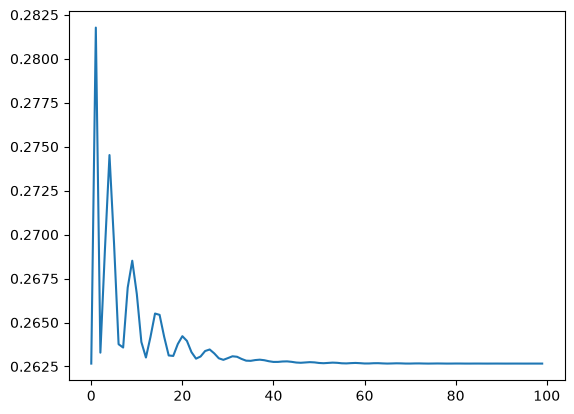

In [44]:
plt.plot(losses)

In [35]:
with torch.inference_mode():
    y_pred=model(x)

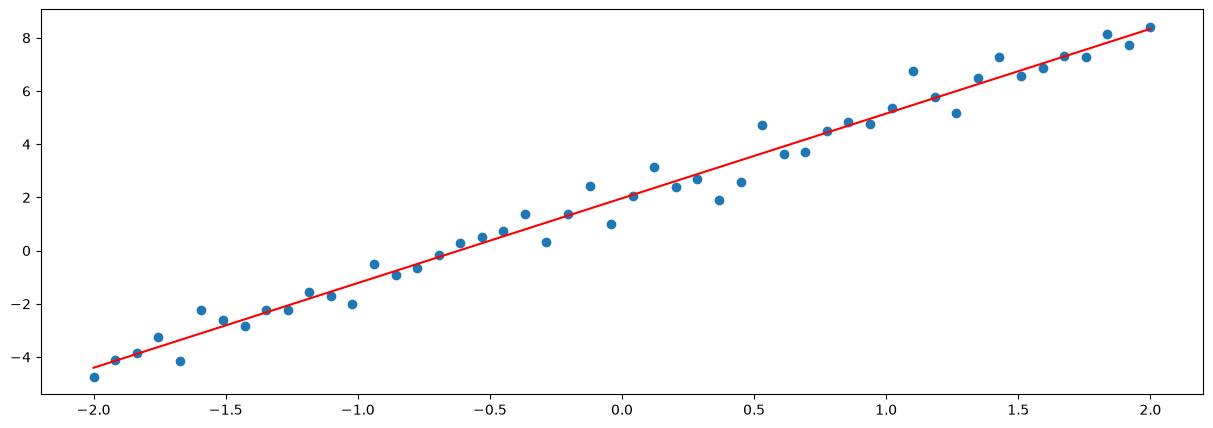

In [36]:
plt.figure(figsize=(15,5))
plt.scatter(x,y)
plt.plot(x,y_pred,color="red",label="Predicted Line")

In [26]:
from torcheval.metrics import R2Score

c:\Users\PC\Desktop\lab_pytorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [37]:
r2_score=R2Score()
r2_score.update(y,y_pred)
score=r2_score.compute()

In [38]:
print(score)

tensor(0.9813)
